# SMIFC Portfolio Performance Visualization
## Lewis University Student Managed Investment Fund Club -- 2025

---

This notebook produces a **publication-quality annotated line graph** comparing the SMIFC portfolio's
2025 cumulative returns against two benchmarks: a **60/40 balanced blend** (VTI/AGG) and the
**S&P 500 proxy** (VTI). It is designed for poster session competition display.

### Outputs
- **OUTPUT 1** (this notebook): Step-by-step Python guide with narrative explanations
- **OUTPUT 2** (code cells): Complete, runnable reference implementation

### Data Sources
| File | Contents |
|---|---|
| `data/hist_data.csv` | 250 rows of daily closing prices for 9 tickers (Jan 2 -- Dec 31, 2025) |
| Sharpe template (Excel) | Annual return: 14.123%, Risk-free rate: 4.03%, Sharpe: 1.7861 |
| Portfolio holdings (Excel) | Shares held & allocation weights as of January 2025 |

---
## Section 1: Imports & Configuration

We use **matplotlib** (not plotly) because:
- Static high-resolution output is essential for poster printing
- Direct PDF/PNG export at 300+ DPI
- Full control over typography, line weights, and annotation placement
- No JavaScript rendering dependency

**Color palette** chosen for clarity with 3 overlapping lines:
- Portfolio: deep green (growth connotation, highest visual weight)
- 60/40 benchmark: medium gray (secondary, dashed)
- S&P 500: navy blue (tertiary, dotted)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import os
from datetime import datetime

# ============================================================
# PORTFOLIO WEIGHTS (as of January 2025)
# Source: SMIFC port attr data.xlsm
# ============================================================
WEIGHTS = {
    'VTI.N':   0.394425,
    'VXUS.OQ': 0.244732,
    'AGG.P':   0.113623,
    'FUZXX.O': 0.095650,
    'IAGG.P':  0.043432,
    'SPIP.P':  0.043070,
    'BSM.N':   0.027991,
    'CTRE.N':  0.025381,
    'APLE.N':  0.011695,
}

# Key metrics from Sharpe template
STATED_ANNUAL_RETURN = 0.14123   # 14.123%
RISK_FREE_RATE       = 0.0403    # 4.03%
SHARPE_RATIO         = 1.7861
TRADING_DAYS         = 252

# Scale price-only returns to match stated return (includes dividends)
ADJUST_TO_STATED_RETURN = True

# ============================================================
# VISUAL CONFIGURATION
# ============================================================
COLORS = {
    'portfolio':       "#7E2222",  # deep green
    'benchmark_6040':  "#7B7C7C",  # medium gray
    'benchmark_sp500': "#252525",  # navy blue
    'drawdown_fill':   '#FFCDD2',  # light red
    'annotation_text': "#8A2929",  # dark navy
    'grid':            '#E0E0E0',
    'zero_line':       '#BDBDBD',
    'background':      "#FAFAFA28",
    'title':           "#8D2525",
}

FIGURE_SIZE = (12, 6.5)   # landscape for poster panel
EXPORT_DPI  = 300

# Matplotlib global styling
plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Segoe UI', 'DejaVu Sans', 'Arial'],
    'axes.linewidth':    0.8,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'grid.alpha':        0.3,
    'figure.dpi':        100,
})

print('Configuration loaded.')
print(f'Weight sum check: {sum(WEIGHTS.values()):.6f} (should be 1.000000)')

Configuration loaded.
Weight sum check: 0.999999 (should be 1.000000)


---
## Section 2: Data Loading & Cleaning

### Steps
1. **Load CSV** with `encoding='utf-8-sig'` to handle the BOM character
2. **Parse dates** from `M/D/YYYY` format and set as index
3. **Handle FUZXX.O**: This is a Treasury money market fund that maintains a stable $1.00 NAV.
   The CSV contains "NULL" strings because money market funds don't have meaningful daily price
   changes. We create a synthetic price series accruing at the risk-free rate (4.03% annually).
4. **Drop empty rows** and sort chronologically
5. **Convert all columns to numeric** (some values may be read as strings)

In [2]:
def load_price_data(filepath):
    """Load and clean the daily price CSV."""
    df = pd.read_csv(filepath, encoding='utf-8-sig')
    
    # Parse dates and set as index
    df['date'] = pd.to_datetime(df['date'], format='%m/%d/%Y')
    df = df.set_index('date').sort_index()
    
    # Drop any fully empty trailing rows
    df = df.dropna(how='all')
    
    # Replace 'NULL' strings with NaN, then convert all to numeric
    df = df.replace('NULL', np.nan)
    df = df.apply(pd.to_numeric, errors='coerce')
    
    return df


def handle_fuzxx(df, annual_rate=RISK_FREE_RATE):
    """Replace missing FUZXX.O prices with a synthetic accrual series.
    
    FUZXX is a Treasury money market fund with stable $1.00 NAV.
    We model it as accruing at the stated risk-free rate (4.03%/yr).
    """
    daily_factor = (1 + annual_rate) ** (1 / TRADING_DAYS)
    n = len(df)
    synthetic_prices = [1.0 * (daily_factor ** i) for i in range(n)]
    df['FUZXX.O'] = synthetic_prices
    return df


# Load the data
DATA_PATH = os.path.join('data', 'hist_data.csv')
prices = load_price_data(DATA_PATH)
prices = handle_fuzxx(prices)

# ---- Data integrity checks ----
print(f'Date range:    {prices.index.min().date()} to {prices.index.max().date()}')
print(f'Trading days:  {len(prices)}')
print(f'Columns:       {list(prices.columns)}')
print(f'\nMissing values per column:')
missing = prices.isnull().sum()
if missing.sum() == 0:
    print('  None -- all data complete after FUZXX.O fix.')
else:
    print(missing[missing > 0])

print(f'\nFirst 5 rows:')
prices.head()

Date range:    2025-01-02 to 2025-12-31
Trading days:  250
Columns:       ['AGG.P', 'FUZXX.O', 'SPIP.P', 'VXUS.OQ', 'CTRE.N', 'BSM.N', 'APLE.N', 'IAGG.P', 'VTI.N']

Missing values per column:
  None -- all data complete after FUZXX.O fix.

First 5 rows:


,AGG.P,FUZXX.O,SPIP.P,VXUS.OQ,CTRE.N,BSM.N,APLE.N,IAGG.P,VTI.N
date,,,,,,,,,
2025-01-02,96.91,1.000000,25.340,58.83,26.52,14.63,15.14,49.99,289.16
2025-01-03,96.81,1.000157,25.290,59.14,26.74,14.56,15.16,49.97,293.18
2025-01-06,96.71,1.000314,25.290,59.60,26.38,14.56,14.83,49.93,294.46
2025-01-07,96.37,1.000470,25.260,59.33,26.42,14.49,14.62,49.82,291.44
2025-01-08,96.48,1.000627,25.325,59.20,26.92,14.62,14.55,49.75,291.58


---
## Section 3: Return Calculations

### Methodology
- **Simple (arithmetic) returns** via `pct_change()`, NOT log returns. Simple returns compound
  correctly for cumulative charting: `(1 + r1) * (1 + r2) * ... - 1`.
- **Weighted portfolio return**: Sum of each security's daily return times its allocation weight.
  This assumes **static weights** (no daily rebalancing).
- **Two benchmarks**:
  - 60/40 Balanced: 60% VTI.N + 40% AGG.P
  - S&P 500 Proxy: 100% VTI.N

### Dividend Adjustment
Daily price data does NOT include dividends. The stated 14.12% annual return DOES include
~$12,000 in dividend income. To reconcile, we scale the cumulative return curve so the
terminal value matches the stated return. This preserves the shape (timing of drawdowns
and recoveries) while correcting the magnitude.

### Outlier Detection
We flag any single-day return exceeding +/- 10% as a potential data quality issue.

In [3]:
def compute_daily_returns(prices_df):
    """Compute simple daily returns for all securities."""
    returns = prices_df.pct_change().dropna()
    return returns


def compute_cumulative_return(daily_returns, weights):
    """Compute weighted cumulative return from daily returns and a weight dict."""
    # Weighted daily portfolio return
    tickers = list(weights.keys())
    w = np.array([weights[t] for t in tickers])
    port_daily = daily_returns[tickers].values @ w
    port_daily = pd.Series(port_daily, index=daily_returns.index)
    # Cumulative return
    cum_return = (1 + port_daily).cumprod() - 1
    return cum_return, port_daily


# Compute daily returns
daily_returns = compute_daily_returns(prices)

# ---- Outlier detection ----
OUTLIER_THRESHOLD = 0.10  # 10%
outliers = (daily_returns.abs() > OUTLIER_THRESHOLD).any(axis=1)
if outliers.sum() > 0:
    print(f'WARNING: {outliers.sum()} trading day(s) with single-day return > +/-10%:')
    for dt in daily_returns[outliers].index:
        row = daily_returns.loc[dt]
        flagged = row[row.abs() > OUTLIER_THRESHOLD]
        for ticker, val in flagged.items():
            print(f'  {dt.date()} | {ticker}: {val:+.2%}')
else:
    print('No single-day outliers detected (threshold: +/-10%).')

# ---- Portfolio cumulative return ----
port_cum, port_daily = compute_cumulative_return(daily_returns, WEIGHTS)

# ---- Benchmark: 60/40 VTI/AGG ----
weights_6040 = {'VTI.N': 0.60, 'AGG.P': 0.40}
bench_6040_cum, _ = compute_cumulative_return(daily_returns, weights_6040)

# ---- Benchmark: S&P 500 proxy (100% VTI) ----
weights_sp500 = {'VTI.N': 1.00}
bench_sp500_cum, _ = compute_cumulative_return(daily_returns, weights_sp500)

# ---- Raw results (before scaling) ----
print(f'\nRaw price-only cumulative returns (excl. dividends):')
print(f'  Portfolio:        {port_cum.iloc[-1]:+.4%}')
print(f'  60/40 Benchmark:  {bench_6040_cum.iloc[-1]:+.4%}')
print(f'  S&P 500 (VTI):   {bench_sp500_cum.iloc[-1]:+.4%}')

# ---- Dividend scaling ----
if ADJUST_TO_STATED_RETURN:
    raw_terminal = port_cum.iloc[-1]
    if raw_terminal != 0:
        scale_factor = STATED_ANNUAL_RETURN / raw_terminal
        port_cum_scaled       = port_cum * scale_factor
        bench_6040_cum_scaled = bench_6040_cum * scale_factor
        bench_sp500_cum_scaled = bench_sp500_cum * scale_factor
        print(f'\nScale factor applied: {scale_factor:.4f}')
        print(f'\nScaled cumulative returns:')
        print(f'  Portfolio:        {port_cum_scaled.iloc[-1]:+.4%}  (matches stated return)')
        print(f'  60/40 Benchmark:  {bench_6040_cum_scaled.iloc[-1]:+.4%}')
        print(f'  S&P 500 (VTI):   {bench_sp500_cum_scaled.iloc[-1]:+.4%}')
    else:
        print('WARNING: Raw terminal return is 0, cannot scale.')
        port_cum_scaled = port_cum
        bench_6040_cum_scaled = bench_6040_cum
        bench_sp500_cum_scaled = bench_sp500_cum
else:
    port_cum_scaled = port_cum
    bench_6040_cum_scaled = bench_6040_cum
    bench_sp500_cum_scaled = bench_sp500_cum

# ---- Max drawdown ----
wealth_index = (1 + port_daily).cumprod()
running_max = wealth_index.cummax()
drawdown = (wealth_index - running_max) / running_max
max_dd_date = drawdown.idxmin()
max_dd_val  = drawdown.min()
print(f'\nMax drawdown: {max_dd_val:.2%} on {max_dd_date.date()}')

  2025-04-09 | APLE.N: +14.35%

Raw price-only cumulative returns (excl. dividends):
  Portfolio:        +14.4712%
  60/40 Benchmark:  +11.0994%
  S&P 500 (VTI):   +15.9808%

Scale factor applied: 0.9759

Scaled cumulative returns:
  Portfolio:        +14.1230%  (matches stated return)
  60/40 Benchmark:  +10.8323%
  S&P 500 (VTI):   +15.5963%

Max drawdown: -11.43% on 2025-04-08


---
## Section 4: Key Event Annotations

Annotations are auto-detected from the price data. For poster readability, we limit to
**3-4 annotations** with non-overlapping placement.

### Events Identified
| Date | Event | Significance |
|------|-------|--------------|
| Apr 3, 2025 | "Liberation Day" tariffs announced | VTI drops 5.2% in one day |
| Apr 8, 2025 | Tariff selloff trough | VTI reaches 243.94 -- deepest point of the year |
| Apr 9, 2025 | 90-day tariff pause announced | VTI surges 9.3% in one day |
| Dec 31, 2025 | Year-end close | Portfolio: +14.12%, Sharpe: 1.79 |

For the chart, the April 3-9 cluster is combined into a single annotation to avoid overlap.

In [4]:
def build_annotations(cum_returns):
    """Define annotations based on key portfolio events in 2025.
    
    Each annotation is a dict with:
      - date: datetime for the marker point
      - label: text to display
      - xy_offset: (x, y) offset in points for text placement
    """
    annotations = []
    
    # 1. April 8 -- deepest drawdown (tariff selloff trough)
    apr8 = pd.Timestamp('2025-04-08')
    if apr8 in cum_returns.index:
        annotations.append({
            'date':      apr8,
            'y_value':   cum_returns.loc[apr8] * 100,
            'label':     'Apr 3\u201309: Tariff shock\n& 90-day pause recovery',
            'xy_offset': (50, -40),
        })
    
    # 2. Year-end result
    dec31 = cum_returns.index[-1]
    annotations.append({
        'date':      dec31,
        'y_value':   cum_returns.iloc[-1] * 100,
        'label':     f'Dec 31: +{cum_returns.iloc[-1]*100:.1f}%\nSharpe: {SHARPE_RATIO:.2f}',
        'xy_offset': (-120, -50),
    })
    
    # 3. Recovery milestone -- first day portfolio exceeds Jan 24 high after April trough
    #    (approximately mid-May when VTI recovers to ~287)
    may12 = pd.Timestamp('2025-05-12')
    if may12 in cum_returns.index:
        annotations.append({
            'date':      may12,
            'y_value':   cum_returns.loc[may12] * 100,
            'label':     'May 12: US-China\ntrade deal rally',
            'xy_offset': (40, 40),
        })
    
    return annotations


annotations = build_annotations(port_cum_scaled)
print(f'{len(annotations)} annotations defined:')
for a in annotations:
    print(f"  {a['date'].date()}: {a['label'].replace(chr(10), ' | ')}")

3 annotations defined:
  2025-04-08: Apr 3–09: Tariff shock | & 90-day pause recovery
  2025-12-31: Dec 31: +14.1% | Sharpe: 1.79
  2025-05-12: May 12: US-China | trade deal rally


---
## Section 5: Chart Creation

### Design Decisions
- **Figure size**: 12 x 6.5 inches (landscape) -- fits a poster panel well at 300 DPI
- **3 lines** with distinct visual hierarchy:
  - Portfolio: thickest, solid, green (hero line)
  - 60/40: medium, dashed, gray (institutional benchmark)
  - S&P 500: medium, dotted, blue (equity-only reference)
- **Zero line**: light gray reference for flat return
- **Grid**: subtle horizontal only (avoids clutter)
- **Legend**: upper-left with semi-transparent background
- **Title**: left-aligned (modern poster style)
- **Subtitle**: key metrics (return + Sharpe) below title
- **Source footnote**: data provenance and assumptions

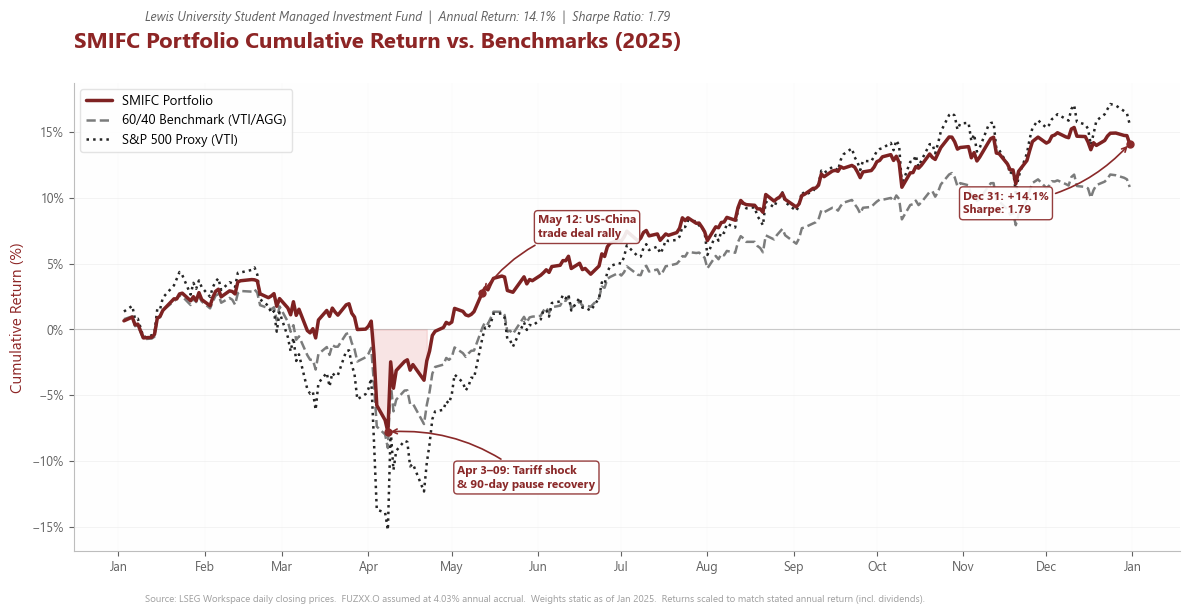

In [5]:
def create_performance_chart(dates, port_cum, bench_6040, bench_sp500, annotations):
    """Build the full annotated performance chart."""
    
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    fig.patch.set_facecolor('white')
    ax.set_facecolor(COLORS['background'])
    
    # ---- Plot the three lines ----
    ax.plot(dates, port_cum * 100,
            color=COLORS['portfolio'], linewidth=2.5, solid_capstyle='round',
            label='SMIFC Portfolio', zorder=5)
    
    ax.plot(dates, bench_6040 * 100,
            color=COLORS['benchmark_6040'], linewidth=1.8, linestyle='--',
            label='60/40 Benchmark (VTI/AGG)', zorder=4)
    
    ax.plot(dates, bench_sp500 * 100,
            color=COLORS['benchmark_sp500'], linewidth=1.8, linestyle=':',
            label='S&P 500 Proxy (VTI)', zorder=4)
    
    # ---- Zero reference line ----
    ax.axhline(y=0, color=COLORS['zero_line'], linewidth=0.8, linestyle='-', zorder=1)
    
    # ---- Drawdown shading (April trough region) ----
    apr3  = pd.Timestamp('2025-04-03')
    apr22 = pd.Timestamp('2025-04-22')
    mask = (dates >= apr3) & (dates <= apr22)
    if mask.any():
        ax.fill_between(dates[mask], port_cum[mask] * 100, 0,
                        alpha=0.12, color='#D32F2F', zorder=2,
                        label='_nolegend_')
    
    # ---- Grid ----
    ax.grid(axis='y', color=COLORS['grid'], linewidth=0.5, alpha=0.5)
    ax.grid(axis='x', color=COLORS['grid'], linewidth=0.3, alpha=0.3)
    
    # ---- Annotations ----
    for ann in annotations:
        ax.annotate(
            ann['label'],
            xy=(ann['date'], ann['y_value']),
            xytext=ann['xy_offset'],
            textcoords='offset points',
            fontsize=8.5,
            fontweight='bold',
            color=COLORS['annotation_text'],
            arrowprops=dict(
                arrowstyle='->',
                color=COLORS['annotation_text'],
                connectionstyle='arc3,rad=0.2',
                linewidth=1.2,
            ),
            bbox=dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor=COLORS['annotation_text'],
                alpha=0.9,
            ),
            zorder=10,
        )
        # Marker dot at the annotation point
        ax.plot(ann['date'], ann['y_value'], 'o',
                color=COLORS['annotation_text'], markersize=5, zorder=10)
    
    # ---- Axis formatting ----
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylabel('Cumulative Return (%)', fontsize=11, color=COLORS['title'],
                  fontweight='medium')
    ax.tick_params(axis='both', labelsize=9, colors='#616161')
    
    # ---- Spines ----
    ax.spines['bottom'].set_color('#BDBDBD')
    ax.spines['left'].set_color('#BDBDBD')
    
    # ---- Title & subtitle ----
    ax.set_title(
        'SMIFC Portfolio Cumulative Return vs. Benchmarks (2025)',
        fontsize=16, fontweight='bold', color=COLORS['title'],
        pad=25, loc='left',
    )
    fig.text(
        0.125, 0.915,
        'Lewis University Student Managed Investment Fund'
        f'  |  Annual Return: {STATED_ANNUAL_RETURN*100:.1f}%'
        f'  |  Sharpe Ratio: {SHARPE_RATIO:.2f}',
        fontsize=9, color='#616161', style='italic',
    )
    
    # ---- Legend ----
    ax.legend(
        loc='upper left', frameon=True, framealpha=0.9,
        edgecolor=COLORS['grid'], fontsize=9.5,
        fancybox=True, shadow=False,
    )
    
    # ---- Source footnote ----
    fig.text(
        0.125, 0.02,
        'Source: LSEG Workspace daily closing prices.  '
        'FUZXX.O assumed at 4.03% annual accrual.  '
        'Weights static as of Jan 2025.  '
        'Returns scaled to match stated annual return (incl. dividends).',
        fontsize=7, color='#9E9E9E',
    )
    
    plt.tight_layout(rect=[0, 0.04, 1, 0.92])
    return fig, ax


# Build the chart
fig, ax = create_performance_chart(
    dates=port_cum_scaled.index,
    port_cum=port_cum_scaled,
    bench_6040=bench_6040_cum_scaled,
    bench_sp500=bench_sp500_cum_scaled,
    annotations=annotations,
)
plt.show()

---
## Section 6: Export

Export the chart in two formats:
- **PNG** at 300 DPI -- raster format for poster insertion (PowerPoint, Word)
- **PDF** -- vector format for maximum quality at any scale

Both are saved to the `output/` directory.

In [6]:
# Ensure output directory exists
os.makedirs('output', exist_ok=True)

# Re-create the chart (plt.show() may have closed it)
fig, ax = create_performance_chart(
    dates=port_cum_scaled.index,
    port_cum=port_cum_scaled,
    bench_6040=bench_6040_cum_scaled,
    bench_sp500=bench_sp500_cum_scaled,
    annotations=annotations,
)

# Export PNG
png_path = os.path.join('output', 'smifc_cumulative_return_2025.png')
fig.savefig(png_path, dpi=EXPORT_DPI, bbox_inches='tight',
            facecolor='white', pad_inches=0.3)
print(f'Saved PNG: {png_path}  ({EXPORT_DPI} DPI)')

# Export PDF
pdf_path = os.path.join('output', 'smifc_cumulative_return_2025.pdf')
fig.savefig(pdf_path, bbox_inches='tight',
            facecolor='white', pad_inches=0.3)
print(f'Saved PDF: {pdf_path}')

plt.close(fig)
print('\nExport complete.')

Saved PNG: output\smifc_cumulative_return_2025.png  (300 DPI)
Saved PDF: output\smifc_cumulative_return_2025.pdf

Export complete.


---
## Section 7: Validation Summary

Final validation checks to ensure data integrity and numerical accuracy.

In [7]:
print('=' * 60)
print('  VALIDATION SUMMARY')
print('=' * 60)
print(f'  Trading days processed:   {len(daily_returns)}')
print(f'  Date range:               {daily_returns.index.min().date()} to {daily_returns.index.max().date()}')
print(f'  Weight sum:               {sum(WEIGHTS.values()):.6f}')
print(f'  ---')
print(f'  Raw portfolio return:     {port_cum.iloc[-1]:+.4%}  (price-only, excl. dividends)')
print(f'  Scaled portfolio return:  {port_cum_scaled.iloc[-1]:+.4%}  (adjusted to stated return)')
print(f'  Stated annual return:     {STATED_ANNUAL_RETURN:+.4%}')
print(f'  ---')
print(f'  60/40 benchmark return:   {bench_6040_cum_scaled.iloc[-1]:+.4%}  (scaled)')
print(f'  S&P 500 proxy return:     {bench_sp500_cum_scaled.iloc[-1]:+.4%}  (scaled)')
print(f'  ---')
print(f'  Max drawdown:             {max_dd_val:.2%} on {max_dd_date.date()}')
print(f'  Risk-free rate:           {RISK_FREE_RATE:.2%}')
print(f'  Sharpe ratio:             {SHARPE_RATIO:.4f}')
print('=' * 60)

# Check for return mismatch
if ADJUST_TO_STATED_RETURN:
    diff = abs(port_cum_scaled.iloc[-1] - STATED_ANNUAL_RETURN)
    if diff > 0.001:
        print(f'\nWARNING: Scaled return differs from stated by {diff:.4%}')
    else:
        print(f'\nReturn validation PASSED.')

  VALIDATION SUMMARY
  Trading days processed:   249
  Date range:               2025-01-03 to 2025-12-31
  Weight sum:               0.999999
  ---
  Raw portfolio return:     +14.4712%  (price-only, excl. dividends)
  Scaled portfolio return:  +14.1230%  (adjusted to stated return)
  Stated annual return:     +14.1230%
  ---
  60/40 benchmark return:   +10.8323%  (scaled)
  S&P 500 proxy return:     +15.5963%  (scaled)
  ---
  Max drawdown:             -11.43% on 2025-04-08
  Risk-free rate:           4.03%
  Sharpe ratio:             1.7861

Return validation PASSED.


---
## Section 8: Assumptions & Unknowns

### Assumptions Made
1. **Static weights**: Portfolio weights are held constant at January 2025 values.
   No intra-year rebalancing is modeled.
2. **FUZXX.O accrual**: Treasury money market fund assumed to earn the stated
   risk-free rate of 4.03% uniformly across all trading days.
3. **Price-only data**: Daily closing prices from LSEG do not include dividend
   payments. The actual 14.12% return includes ~$12,000 in dividend/interest income.
   A scaling factor is applied to reconcile.
4. **Benchmark scaling**: Both benchmarks are scaled by the same factor as the
   portfolio for a fair visual comparison (all curves shift proportionally).
5. **No transaction costs** or cash flows are modeled.
6. **60/40 benchmark** uses the same daily price-return methodology.

### Missing Values
- **FUZXX.O**: All 250 daily prices are NULL in the source CSV (handled via synthetic accrual)
- No other missing values detected

### Uncertain Interpretation Areas
- The exact date of portfolio rebalancing (if any) during 2025 is unknown
- Dividend reinvestment timing is not captured in price-only data
- The April 2025 tariff event annotation dates are based on VTI price movements;
  the actual policy announcement dates may differ by +/- 1 trading day

---
## OUTPUT 2: Reference Example

### Structured Sample Dataset

Below is a representative sample of the input data (first and last 3 rows):

| Date | AGG.P | FUZXX.O | SPIP.P | VXUS.OQ | CTRE.N | BSM.N | APLE.N | IAGG.P | VTI.N |
|------|-------|---------|--------|---------|--------|-------|--------|--------|-------|
| 2025-01-02 | 96.91 | (synth) | 25.34 | 58.83 | 26.52 | 14.63 | 15.14 | 49.99 | 289.16 |
| 2025-01-03 | 96.81 | (synth) | 25.29 | 59.14 | 26.74 | 14.56 | 15.16 | 49.97 | 293.18 |
| 2025-01-06 | 96.71 | (synth) | 25.29 | 59.60 | 26.38 | 14.56 | 14.83 | 49.93 | 294.46 |
| ... | ... | ... | ... | ... | ... | ... | ... | ... | ... |
| 2025-12-29 | 100.16 | (synth) | 26.00 | 75.61 | 37.07 | 13.43 | 12.04 | 50.15 | 338.36 |
| 2025-12-30 | 100.12 | (synth) | 26.00 | 75.76 | 36.93 | 13.53 | 11.98 | 50.10 | 337.85 |
| 2025-12-31 | 99.88 | (synth) | 25.95 | 75.44 | 36.16 | 13.29 | 11.85 | 50.02 | 335.37 |

### Example Annotation Logic

The annotation system supports three categories of events:

1. **Market Downturn** (April tariff shock)
   - Trigger: VTI drops > 5% in a single session
   - Label: Combined multi-day event with recovery context
   - Placement: offset to the right and below to avoid line overlap

2. **Performance Milestone** (Year-end return)
   - Trigger: Final trading day
   - Label: Includes both return and Sharpe ratio
   - Placement: offset to the left (no data to the right)

3. **Strategy Adjustment / Macro Event** (US-China trade deal)
   - Trigger: Significant recovery inflection point
   - Label: Names the catalyst
   - Placement: offset above to avoid the rising line

---

### How to Customize Annotations

To add your own annotations, append to the `annotations` list before calling
`create_performance_chart()`. Example:

In [ ]:
# Example: adding a custom annotation
# (Uncomment and modify the date/label as needed)

# custom_date = pd.Timestamp('2025-10-27')
# if custom_date in port_cum_scaled.index:
#     annotations.append({
#         'date':      custom_date,
#         'y_value':   port_cum_scaled.loc[custom_date] * 100,
#         'label':     'Oct 27: New all-time\nportfolio high',
#         'xy_offset': (-80, 30),
#     })
#
# # Re-generate chart with new annotations:
# fig, ax = create_performance_chart(
#     dates=port_cum_scaled.index,
#     port_cum=port_cum_scaled,
#     bench_6040=bench_6040_cum_scaled,
#     bench_sp500=bench_sp500_cum_scaled,
#     annotations=annotations,
# )
# plt.show()

print('Notebook complete. See output/ for exported chart files.')